# IMPORT LIBRARY

In [ ]:
import pandas as pd
import numpy as np

# IMPORT DATASET

In [ ]:
data = pd.read_csv('/content/co2_polution.csv')

In [ ]:
data.head()

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg,co2
0,PICKUP TRUCK - STANDARD,5.3,8,Regular gasoline,14.6,10.3,12.7,22.0,298.0
1,MID-SIZE,2.4,4,Regular gasoline,9.1,6.8,8.0,35.0,187.0
2,PICKUP TRUCK - SMALL,3.6,6,Regular gasoline,13.0,9.2,11.3,25.0,265.0
3,MID-SIZE,2.0,4,Premium gasoline,10.5,7.6,9.2,31.0,215.0
4,MID-SIZE,2.0,4,Diesel,7.8,5.3,6.7,42.0,182.0


In [ ]:
#Menampilkan dimensi dataset (ukuran tabel dataset)

data.shape

(4938, 9)

In [ ]:
#Cek nama colom dalam dataset

data.columns

Index(['vehicle_class', 'engine_size', 'cylinders', 'fuel_type',
       'fuel_cons_city', 'fuel_cons_hwy', 'fuel_cons_comb',
       'fuel_cons_comb_mpg', 'co2'],
      dtype='object')

In [ ]:
#Menampilkan informasi dataset

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4938 entries, 0 to 4937
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   vehicle_class       4938 non-null   object 
 1   engine_size         4925 non-null   float64
 2   cylinders           4938 non-null   int64  
 3   fuel_type           4938 non-null   object 
 4   fuel_cons_city      4934 non-null   float64
 5   fuel_cons_hwy       4919 non-null   float64
 6   fuel_cons_comb      4938 non-null   float64
 7   fuel_cons_comb_mpg  4938 non-null   float64
 8   co2                 4938 non-null   float64
dtypes: float64(6), int64(1), object(2)
memory usage: 347.3+ KB


In [ ]:
#Menampilkan jumlah nilai unik dari setiap kolom

data.nunique()

,0
vehicle_class,16
engine_size,148
cylinders,16
fuel_type,4
fuel_cons_city,308
fuel_cons_hwy,240
fuel_cons_comb,278
fuel_cons_comb_mpg,151
co2,428


# Missing Data

In [ ]:
#Cek data yang kosong

data.isna().sum()

,0
vehicle_class,0
engine_size,13
cylinders,0
fuel_type,0
fuel_cons_city,4
fuel_cons_hwy,19
fuel_cons_comb,0
fuel_cons_comb_mpg,0
co2,0


In [ ]:
data[data['fuel_cons_city'].isna()]

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg,co2
625,STATION WAGON - SMALL,1.5,4,Regular gasoline,NaN,6.9,7.7,37.0,177.0
641,SUV - SMALL,3.7,6,Premium gasoline,NaN,10.7,12.8,22.0,294.0
1180,FULL-SIZE,2.0,4,Regular gasoline,NaN,4.6,5.0,56.0,117.0
3935,SUV - STANDARD,5.6,8,Regular gasoline,NaN,13.4,16.6,17.0,382.0


In [ ]:
#Mencari mean dari setiap data yang kosong

data_copy = data.copy(deep=True)
mean_engine = data_copy['engine_size'].mean()
mean_city = data_copy['fuel_cons_city'].mean()
mean_hwy = data_copy['fuel_cons_hwy'].mean()

In [ ]:
print(f"Mean of engine size : {mean_engine}")
print(f"Mean of fuel cons city : {mean_city}")
print(f"Mean of fuel cons hwy : {mean_hwy}")

In [ ]:
#Mengisi data yang kosong dengan mean setiap kolom yang memiliki data kosong

data_copy.fillna({
    'engine_size' : mean_engine,
    'fuel_cons_city' : mean_city,
    'fuel_cons_hwy' : mean_hwy
}, inplace=True)

In [ ]:
data_copy[data['fuel_cons_city'].isna()]

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg,co2
625,STATION WAGON - SMALL,1.5,4,Regular gasoline,12.504822,6.9,7.7,37.0,177.0
641,SUV - SMALL,3.7,6,Premium gasoline,12.504822,10.7,12.8,22.0,294.0
1180,FULL-SIZE,2.0,4,Regular gasoline,12.504822,4.6,5.0,56.0,117.0
3935,SUV - STANDARD,5.6,8,Regular gasoline,12.504822,13.4,16.6,17.0,382.0


In [ ]:
data_copy.isna().sum()

,0
vehicle_class,0
engine_size,0
cylinders,0
fuel_type,0
fuel_cons_city,0
fuel_cons_hwy,0
fuel_cons_comb,0
fuel_cons_comb_mpg,0
co2,0


In [ ]:
#Mengisi data yang kosong menggunakan algoritma K-Nearest Neighbors

from sklearn.impute import KNNImputer

null_colom = ['engine_size', 'fuel_cons_city', 'fuel_cons_hwy']

imputer = KNNImputer(n_neighbors=5)
data[null_colom] = imputer.fit_transform(data[null_colom])

In [ ]:
data.isna().sum()

,0
vehicle_class,0
engine_size,0
cylinders,0
fuel_type,0
fuel_cons_city,0
fuel_cons_hwy,0
fuel_cons_comb,0
fuel_cons_comb_mpg,0
co2,0


KNN diatas menggunakan 5 tetangga terdekat

# DATA DUPLIKAT

In [ ]:
data[data.duplicated]

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg,co2
2444,MINICOMPACT,3.8,6,Premium gasoline,13.0,9.2,11.3,25.0,260.0
4213,MINICOMPACT,3.8,6,Premium gasoline,13.0,9.2,11.3,25.0,260.0
4790,MINICOMPACT,3.8,6,Premium gasoline,13.0,9.2,11.3,25.0,260.0


In [ ]:
#Membuang data yang terduplikat

data_karakter = data.select_dtypes(include=['object'])
data_karakter.columns

Index(['vehicle_class', 'fuel_type'], dtype='object')

In [ ]:
#Mengecek kolom dengan tipe data numerik

data_numerik = data.select_dtypes(include=['int64', 'float'])
data_numerik.columns

Index(['engine_size', 'cylinders', 'fuel_cons_city', 'fuel_cons_hwy',
       'fuel_cons_comb', 'fuel_cons_comb_mpg', 'co2'],
      dtype='object')

# LABEL ENDCODING

In [ ]:
data.head()

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg,co2
0,PICKUP TRUCK - STANDARD,5.3,8,Regular gasoline,14.6,10.3,12.7,22.0,298.0
1,MID-SIZE,2.4,4,Regular gasoline,9.1,6.8,8.0,35.0,187.0
2,PICKUP TRUCK - SMALL,3.6,6,Regular gasoline,13.0,9.2,11.3,25.0,265.0
3,MID-SIZE,2.0,4,Premium gasoline,10.5,7.6,9.2,31.0,215.0
4,MID-SIZE,2.0,4,Diesel,7.8,5.3,6.7,42.0,182.0


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
data['vehicle_class'] = encoder.fit_transform(data['vehicle_class'])
data['fuel_type'] = encoder.fit_transform(data['fuel_type'])

In [ ]:
#Melihat statistika deskriptif tiap kolom

data.describe()

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg,co2
count,4938.000000,4938.000000,4938.000000,4938.000000,4938.000000,4938.000000,4938.000000,4938.000000,4938.000000
mean,6.172134,3.109727,5.597610,2.384771,12.504660,9.008082,10.899785,28.076108,248.547590
std,4.787434,1.381849,2.004423,0.713443,3.734715,2.393242,3.031178,7.808277,61.081857
min,0.000000,-0.033955,2.000000,0.000000,3.400683,3.140139,3.165062,10.031223,96.000000
25%,2.000000,2.000000,4.000000,2.000000,9.900000,7.400000,8.800000,23.000000,204.000000
50%,6.000000,3.000000,6.000000,2.000000,11.900000,8.600000,10.400000,27.000000,242.000000
75%,11.000000,3.600000,6.000000,3.000000,14.400000,10.100000,12.500000,32.000000,285.000000
max,15.000000,9.373928,17.000000,3.000000,31.481611,21.339620,27.002350,69.175420,522.000000


# VISUALISASI DATA

In [ ]:
# import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

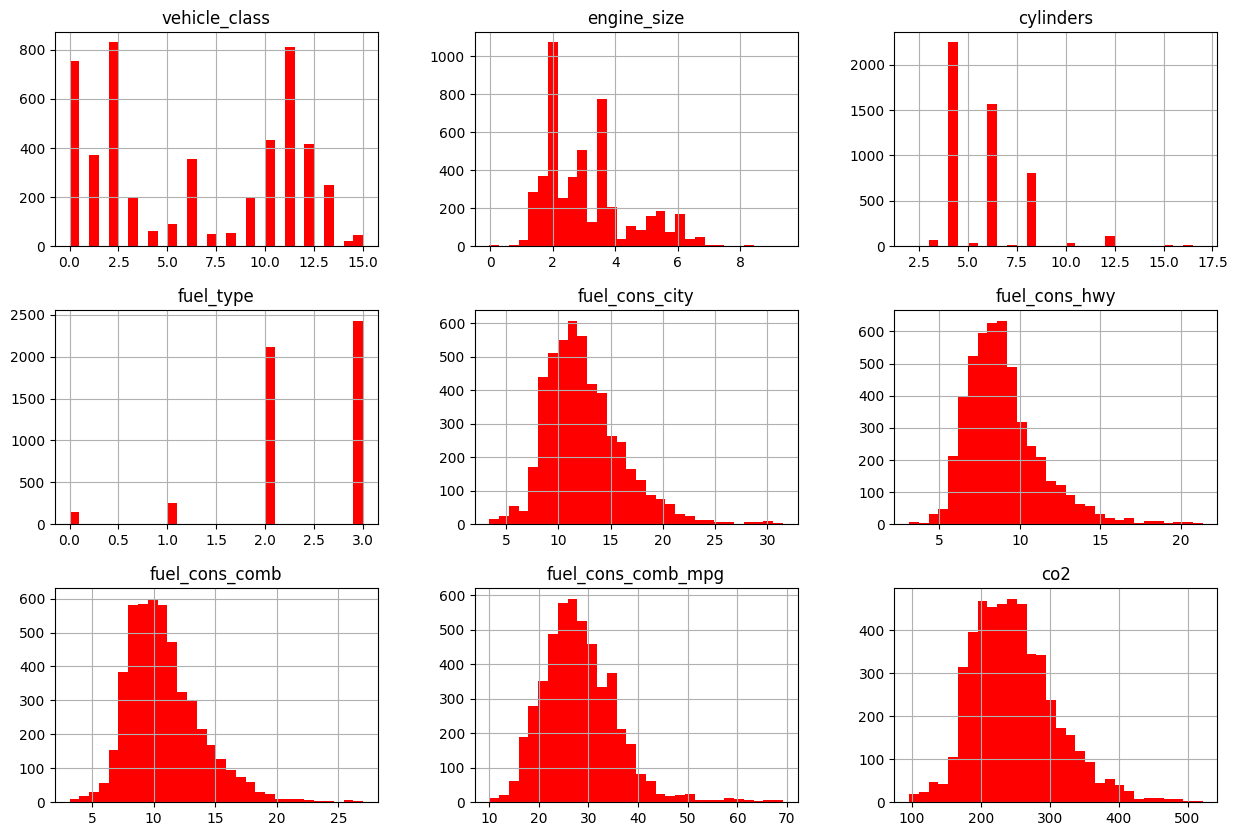

In [ ]:
# visualisasi menggunakan histogram untuk melihat distribusi data
data.hist(figsize=(15, 10), bins=30,color='red');

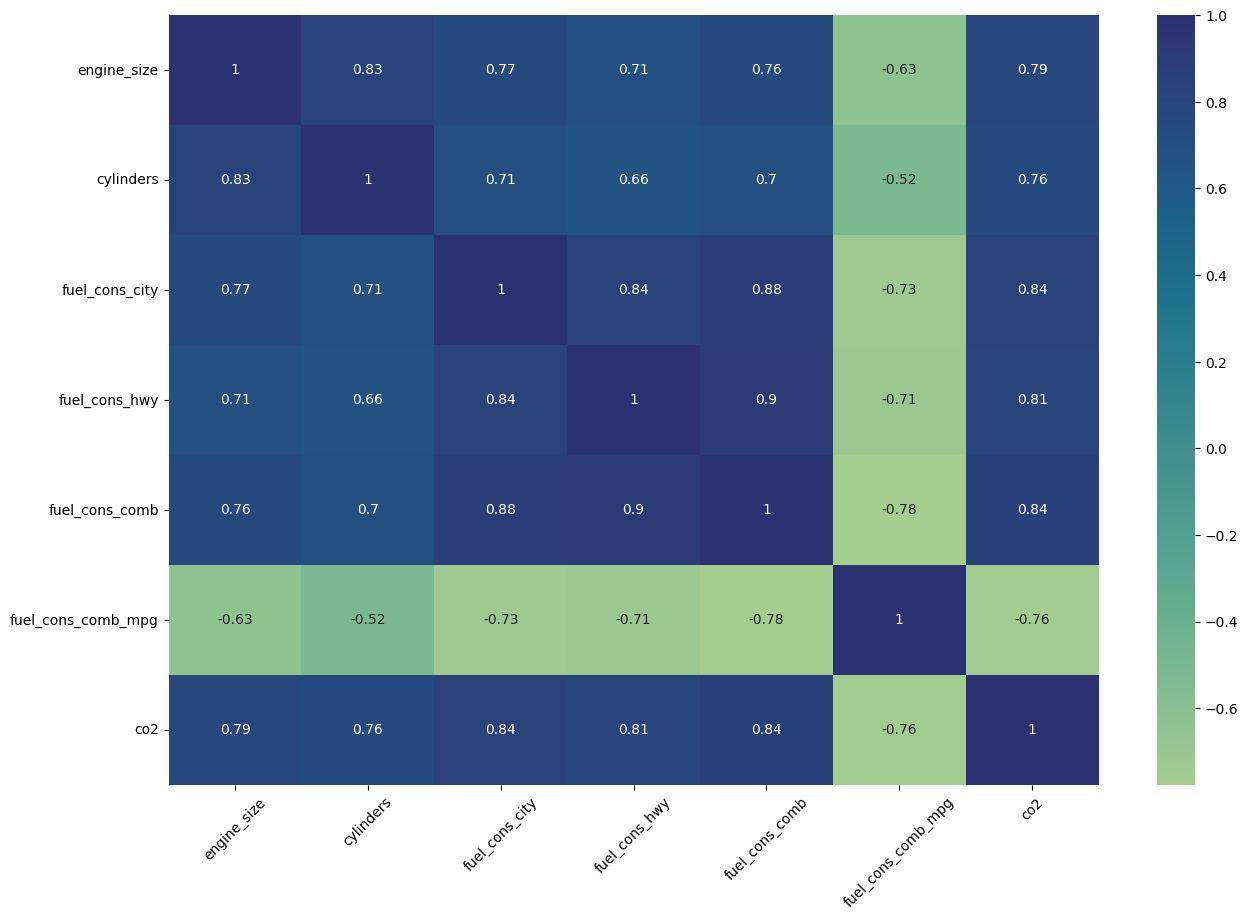

In [ ]:
#visualisasi menggunakan headmap untuk melihat korelasi antar variabel

plt.figure(figsize=(15, 10))
sns.heatmap(data_numerik.corr(), annot=True, cmap='crest')
plt.xticks(rotation=45)
plt.show()

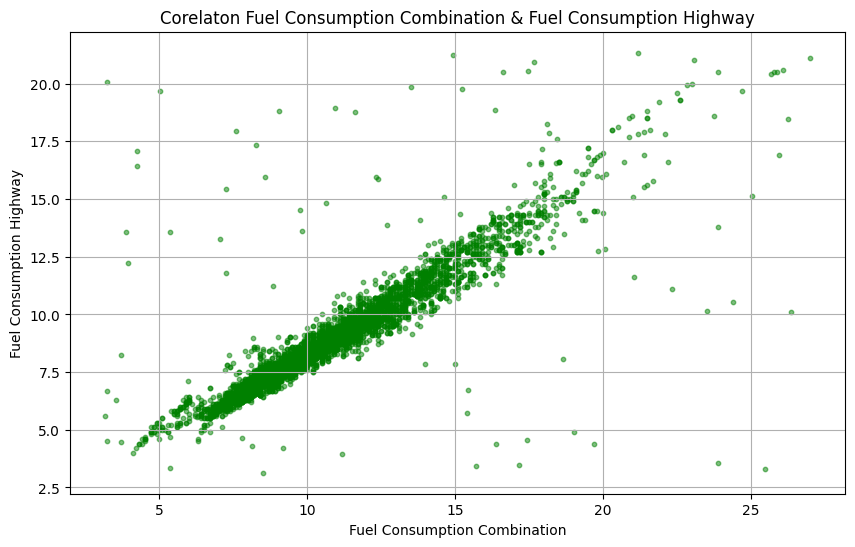

In [ ]:
# visualisasi korelasi positif menggunakan scatterplot
plt.figure(figsize=(10, 6))
plt.scatter(x=data['fuel_cons_comb'], y=data['fuel_cons_hwy'], color='green', alpha=0.5, s=10)
plt.title('Corelaton Fuel Consumption Combination & Fuel Consumption Highway')
plt.xlabel('Fuel Consumption Combination')
plt.ylabel('Fuel Consumption Highway')
plt.grid(True)
plt.show()

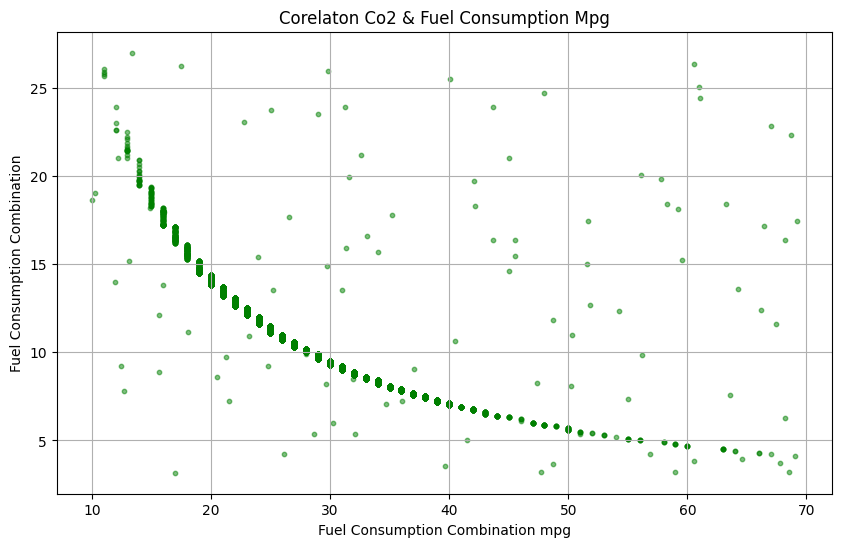

In [ ]:
# visualisasi korelasi negatif menggunakan scatterplot
plt.figure(figsize=(10, 6))
plt.scatter(x=data['fuel_cons_comb_mpg'], y=data['fuel_cons_comb'], color='green', alpha=0.5, s=10)
plt.title('Corelaton Co2 & Fuel Consumption Mpg')
plt.xlabel('Fuel Consumption Combination mpg')
plt.ylabel('Fuel Consumption Combination')
plt.grid(True)
plt.show()

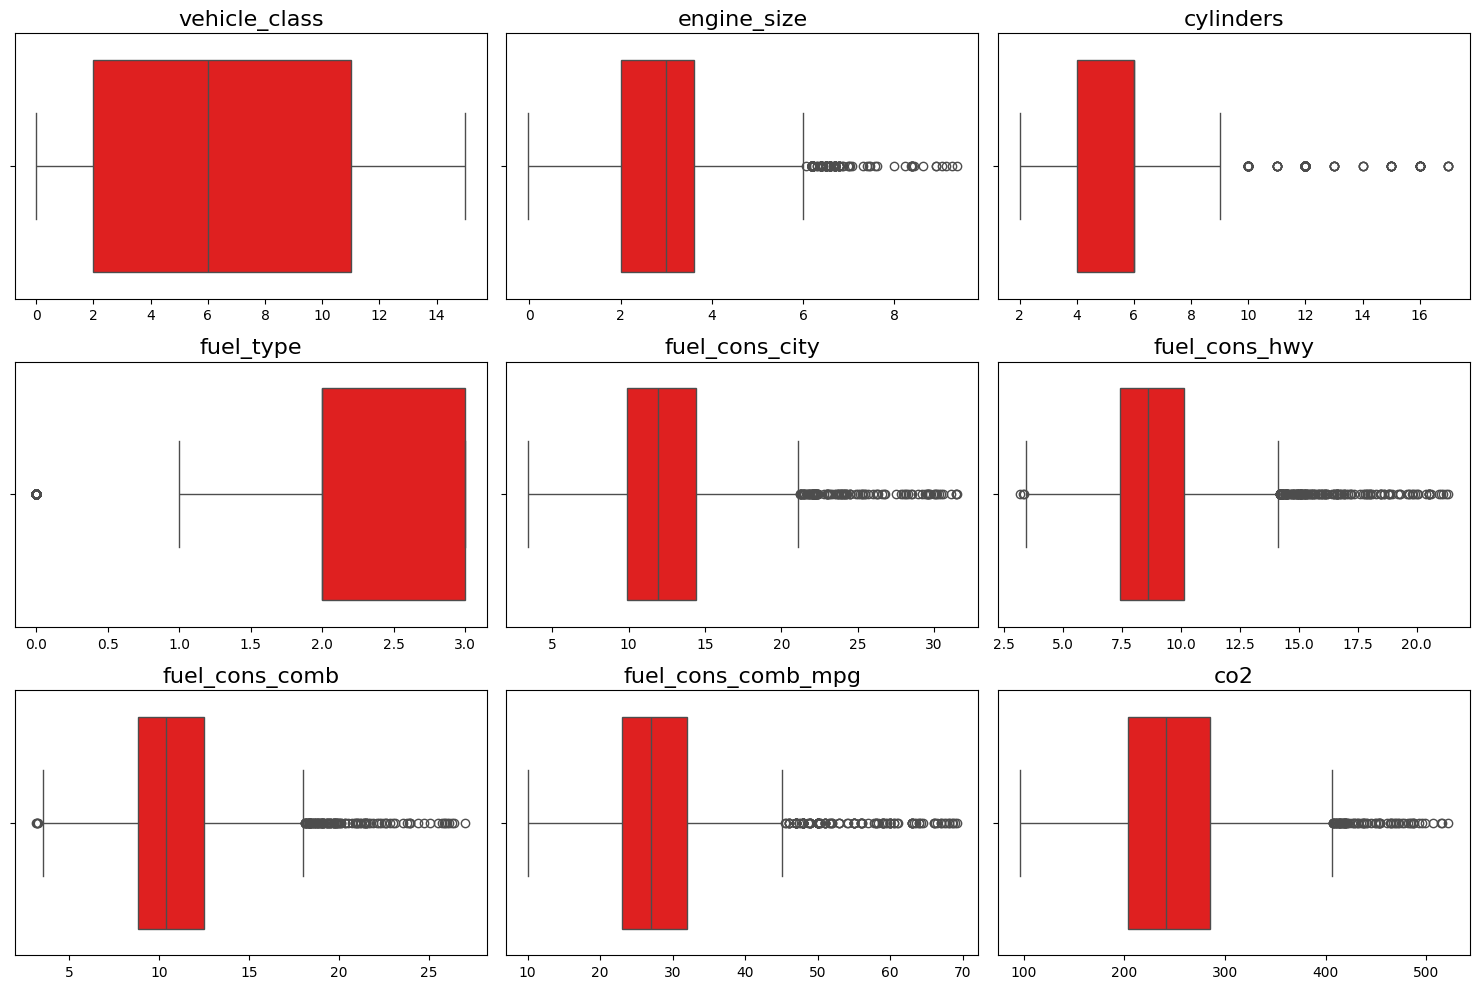

In [ ]:
# visualisasi menggunakan boxplot untuk melihat data outliers
fig, ax = plt.subplots(3, 3, figsize=(15, 10))
ax = ax.flatten()

for i, col in enumerate(data.columns):
    sns.boxplot(data=data, x=data[col], color='red', ax=ax[i])
    ax[i].set_title(col, fontsize=16)
    ax[i].set_xlabel('')

plt.tight_layout()
plt.show()

yang titik titik diatas merupakan outlayer dari sebuah data, atau data ekstrim dimana sebuah data berbeda jauh dari pola data biasanya

# Outliers Handling

In [ ]:
# Menangani data outlier dengan mengubah nilai outlier ke nilai kuartil terdekat(Kuartil 1 dan Kuartil 3).

def iqr_outliers(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR
    data[col] = data[col].mask(data[col] < lower_bound, Q1)
    data[col] = data[col].mask(data[col] > upper_bound, Q3)
    return data

for col in data.columns:
    iqr_outliers(data, col)

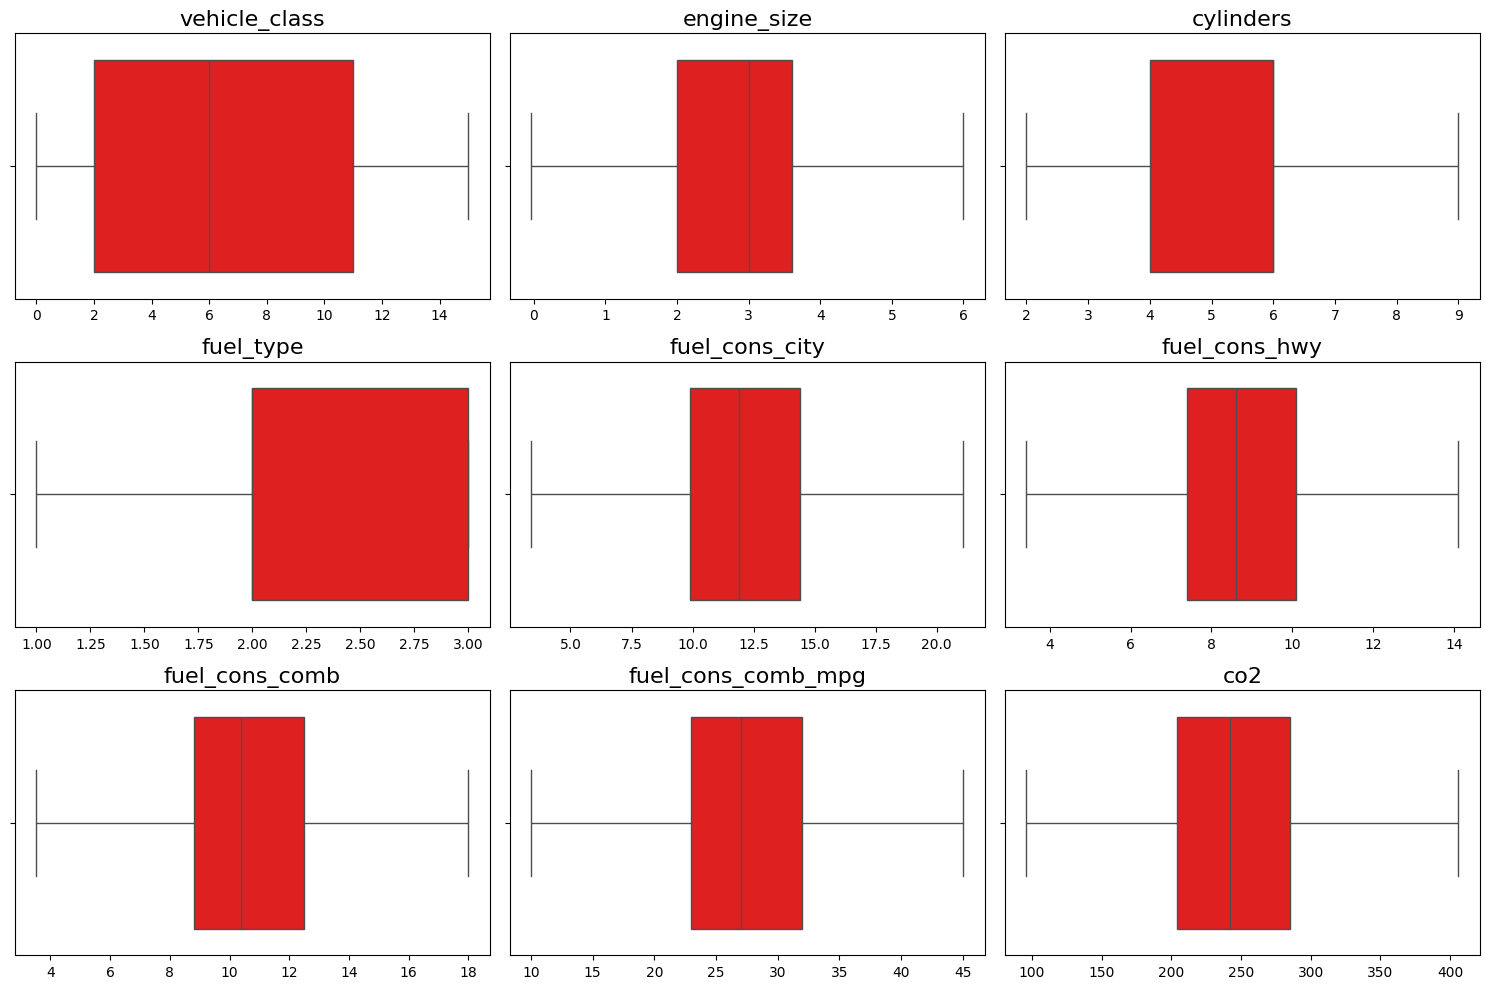

In [ ]:
fig, ax = plt.subplots(3, 3, figsize=(15, 10))
ax = ax.flatten()

for i, col in enumerate(data.columns):
    sns.boxplot(data=data, x=data[col], color='red', ax=ax[i])
    ax[i].set_title(col, fontsize=16)
    ax[i].set_xlabel('')

plt.tight_layout()
plt.show()

bloxpot setelah outliers handling, sudah tidak ada data outliers (yang titik titik)

# Normalisasi & Scalling Data

Menyesuaikan nilai - nilai fitur dalam dataset sehingga memiliki rentab=ng yang seragam

In [ ]:
#membagi data fitur dan data target

x = data.drop('co2', axis=1)
y = data['co2']

In [ ]:
x.head()

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg
0,6,5.3,8,3,14.6,10.3,12.7,22.0
1,2,2.4,4,3,9.1,6.8,8.0,35.0
2,5,3.6,6,3,13.0,9.2,11.3,25.0
3,2,2.0,4,2,10.5,7.6,9.2,31.0
4,2,2.0,4,2,7.8,5.3,6.7,42.0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)

In [ ]:
x_scaled = pd.DataFrame(x_scaled, columns=x.columns)

In [ ]:
x_scaled.head()

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg
0,0.400000,0.883990,0.857143,1.0,0.632754,0.643811,0.633629,0.341762
1,0.133333,0.403376,0.285714,1.0,0.322008,0.315864,0.308733,0.712971
2,0.333333,0.602251,0.571429,1.0,0.542355,0.540742,0.536851,0.427426
3,0.133333,0.337085,0.285714,0.5,0.401107,0.390823,0.391685,0.598753
4,0.133333,0.337085,0.285714,0.5,0.248559,0.175315,0.218868,0.912853


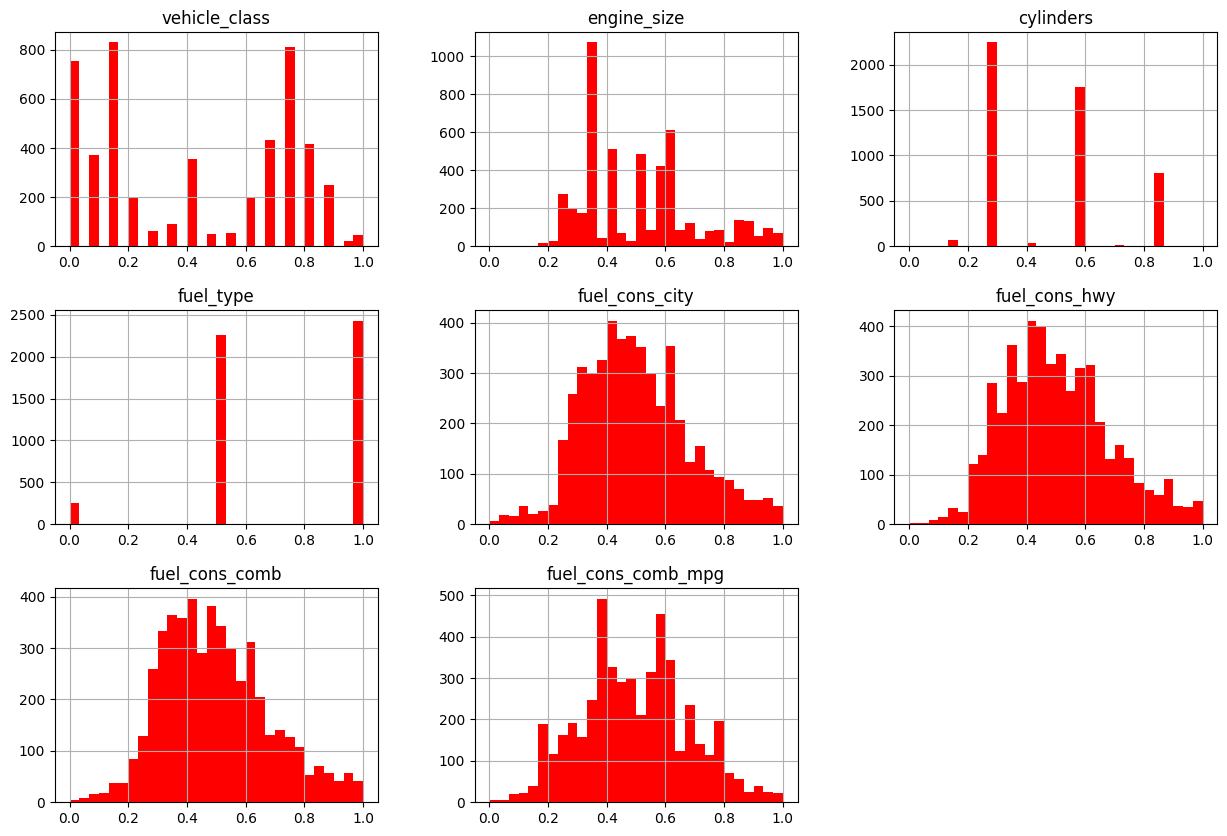

In [ ]:
x_scaled.hist(figsize=(15, 10), bins=30,color='red');

# Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2,
                                                    random_state=42)

In [ ]:
# proporsi pembagian data training
print(x_train.shape)
print(x_train.shape[0]/len(data)*100, '%')

# proporsi pembagian data test
print(x_test.shape)
print(x_test.shape[0]/len(data)*100, '%')

(3950, 8)
79.9918995544755 %
(988, 8)
20.008100445524505 %


In [ ]:
x_train.head()

,vehicle_class,engine_size,cylinders,fuel_type,fuel_cons_city,fuel_cons_hwy,fuel_cons_comb,fuel_cons_comb_mpg
2231,0.133333,0.337085,0.285714,0.5,0.384157,0.372083,0.377860,0.598753
1115,0.133333,0.502814,0.571429,0.5,0.655354,0.615701,0.626716,0.341762
4623,0.866667,0.337085,0.285714,0.5,0.344607,0.353343,0.343296,0.655862
1945,0.000000,0.337085,0.285714,1.0,0.361557,0.334603,0.343296,0.655862
1545,0.733333,0.337085,0.285714,0.5,0.440656,0.456412,0.440074,0.541644


In [ ]:
y_train.head()

,co2
2231,210.0
1115,295.0
4623,200.0
1945,200.0
1545,232.0


In [ ]:
# import model
from sklearn.linear_model import LinearRegression

# inisiasi model linear regression
model_linear = LinearRegression()

# melatih model dengan data training
model_linear.fit(x_train, y_train)

# menguji model dengan memprediksi data test
y_pred_lr = model_linear.predict(x_test)

# Modelling Additional Notes

In [ ]:
# nilai intercept(b) pada model
model_linear.intercept_

117.57549215233482

In [ ]:
# nilai slope(m) pada model
linear_coef = pd.DataFrame({'Columns':x.columns, 'Coefficient':model_linear.coef_})
linear_coef

,Columns,Coefficient
0,vehicle_class,7.112471
1,engine_size,1.587206
2,cylinders,49.196529
3,fuel_type,19.142760
4,fuel_cons_city,108.435476
5,fuel_cons_hwy,60.075208
6,fuel_cons_comb,46.555585
7,fuel_cons_comb_mpg,-40.305994


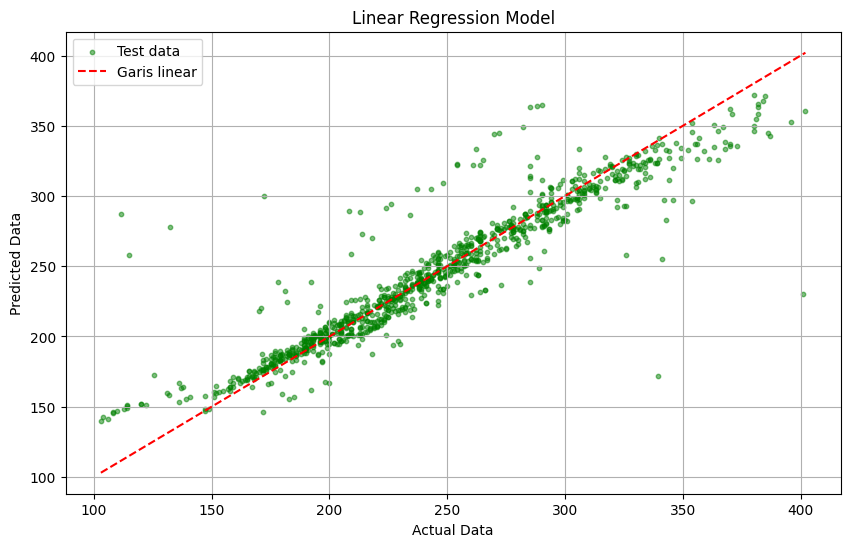

In [ ]:
# visualisasi scatterplot untuk mengevaluasi kinerja model regresi dalam memprediksi data

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_lr, color='green', label='Test data', alpha=0.5, s=10)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label='Garis linear', linestyle= '--')
plt.title('Linear Regression Model')
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# import library yang digunakan untuk evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

mae_linear = mean_absolute_error(y_test, y_pred_lr)
mse_linear = mean_squared_error(y_test, y_pred_lr)
rms_linear = root_mean_squared_error(y_test, y_pred_lr)
r2_linear = r2_score(y_test, y_pred_lr)

print('mean absolute error:', mae_linear)
print('mean squared error:', mse_linear)
print('root mean squared error:', rms_linear)
print('r2 score:', r2_linear)

mean absolute error: 11.210929191129331
mean squared error: 425.85941447301497
root mean squared error: 20.636361464003652
r2 score: 0.8646747244690968


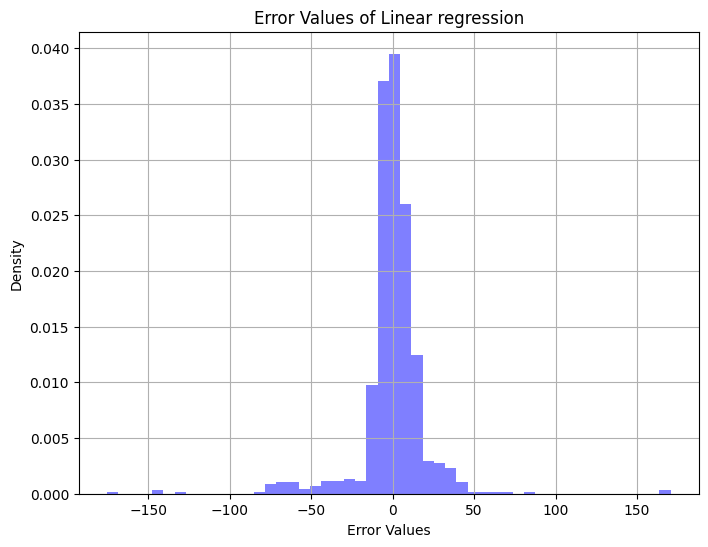

In [ ]:
# visualisasi distribusi error antara nilai aktual dan prediksi model
error_values_lr = y_test - y_pred_lr

plt.figure(figsize=(8, 6))
plt.hist(error_values_lr, bins=50, density=True, color='blue', alpha=0.5)
plt.title('Error Values of Linear regression')
plt.xlabel('Error Values')
plt.ylabel('Density')
plt.grid(True)
plt.show()

In [ ]:
# import model
from sklearn.linear_model import Ridge

# inisialisasi model ridge regression
model_ridge = Ridge(alpha=0.5)

# melatih model dengan data training
model_ridge.fit(x_train, y_train)

# menguji model dengan memprediksi data test
y_pred_rd = model_ridge.predict(x_test)

In [ ]:
# nilai intercept(b) pada model
model_ridge.intercept_

118.2972553439293

In [ ]:
# nilai slope(m) pada model
ridge_coef = pd.DataFrame({'Columns':x.columns, 'Coefficient':model_ridge.coef_})
ridge_coef

,Columns,Coefficient
0,vehicle_class,7.118321
1,engine_size,2.369095
2,cylinders,48.854570
3,fuel_type,18.980127
4,fuel_cons_city,105.871684
5,fuel_cons_hwy,59.725338
6,fuel_cons_comb,48.251177
7,fuel_cons_comb_mpg,-40.744135


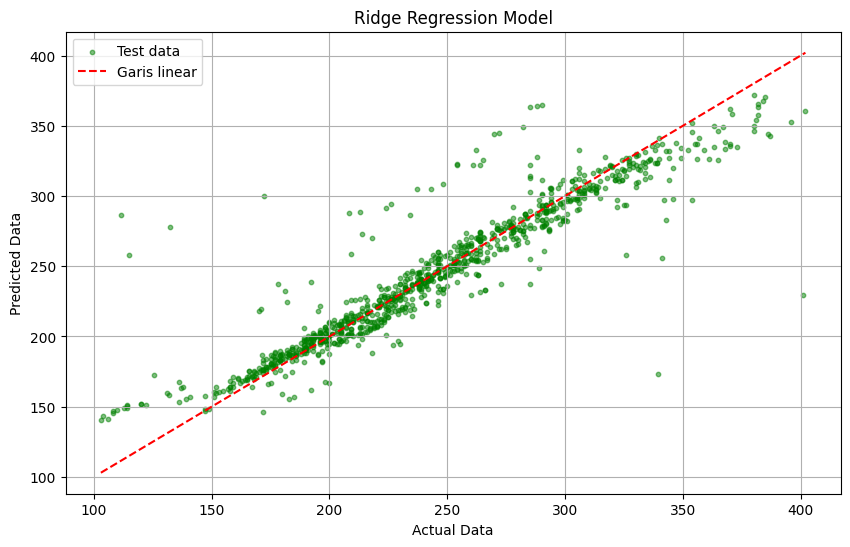

In [ ]:
# visualisasi scatterplot untuk mengevaluasi kinerja model regresi dalam memprediksi data

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_rd, color='green', label='Test data', alpha=0.5, s=10)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label='Garis linear', linestyle= '--')
plt.title('Ridge Regression Model')
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# evaluasi model
mae_ridge = mean_absolute_error(y_test, y_pred_rd)
mse_ridge = mean_squared_error(y_test, y_pred_rd)
rms_ridge = root_mean_squared_error(y_test, y_pred_rd)
r2_ridge = r2_score(y_test, y_pred_rd)

print('mean absolute error:', mae_ridge)
print('mean squared error:', mse_ridge)
print('root mean squared error:', rms_ridge)
print('r2 score:', r2_ridge)

mean absolute error: 11.21833050421057
mean squared error: 425.59030203017466
root mean squared error: 20.629840087363128
r2 score: 0.8647602402854401


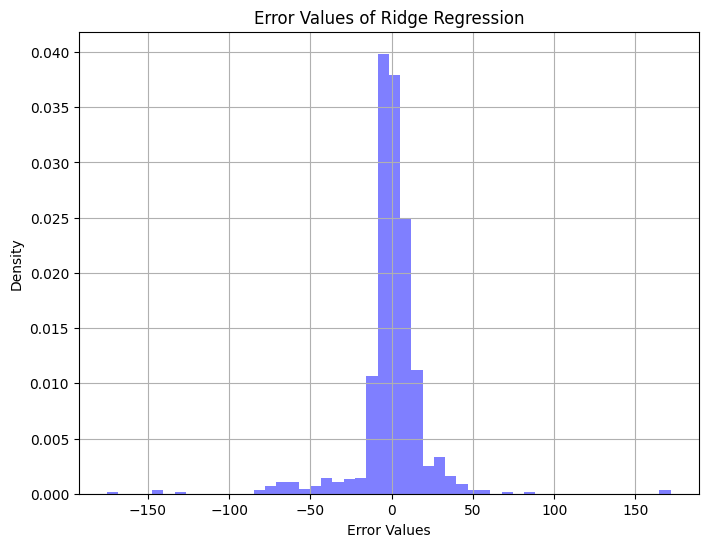

In [ ]:
# visualisasi distribusi error antara nilai aktual dan prediksi model
error_values_rd = y_test - y_pred_rd

plt.figure(figsize=(8, 6))
plt.hist(error_values_rd, bins=50, density=True, color='blue', alpha=0.5)
plt.title('Error Values of Ridge Regression')
plt.xlabel('Error Values')
plt.ylabel('Density')
plt.grid(True)
plt.show()

In [ ]:
# import model
from sklearn.linear_model import Lasso

# inisialisasi model lasso regression
model_lasso = Lasso(alpha=0.5)

# melatih model dengan data training
model_lasso.fit(x_train, y_train)

# menguji model dengan memprediksi data test
y_pred_ls = model_lasso.predict(x_test)

In [ ]:
# nilai intercept(b) pada model
model_lasso.intercept_

133.38021323813393

In [ ]:
# nilai slope(m) pada model
lasso_coef = pd.DataFrame({'Columns':x.columns, 'Coefficient':model_lasso.coef_})
lasso_coef

,Columns,Coefficient
0,vehicle_class,4.871912
1,engine_size,1.054199
2,cylinders,47.577633
3,fuel_type,7.877282
4,fuel_cons_city,96.796943
5,fuel_cons_hwy,59.291657
6,fuel_cons_comb,42.783893
7,fuel_cons_comb_mpg,-35.551588


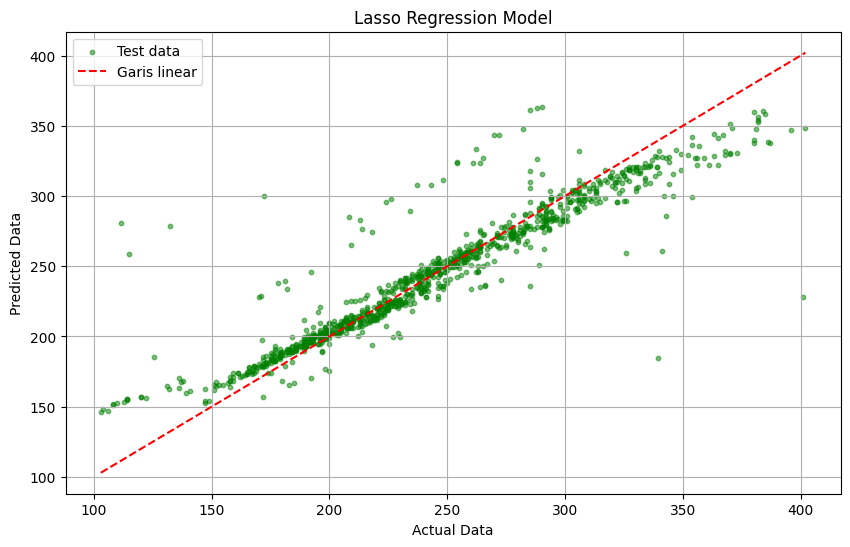

In [ ]:
# visualisasi scatterplot untuk mengevaluasi kinerja model regresi dalam memprediksi data

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_ls, color='green', label='Test data', alpha=0.5, s=10)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', label='Garis linear', linestyle= '--')
plt.title('Lasso Regression Model')
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# evaluasi model
mae_lasso = mean_absolute_error(y_test, y_pred_ls)
mse_lasso = mean_squared_error(y_test, y_pred_ls)
rms_lasso = root_mean_squared_error(y_test, y_pred_ls)
r2_lasso = r2_score(y_test, y_pred_ls)

print('mean absolute error:', mae_lasso)
print('mean squared error:', mse_lasso)
print('root mean squared error:', rms_lasso)
print('r2 score:', r2_lasso)

mean absolute error: 11.795626207466581
mean squared error: 446.9730636064837
root mean squared error: 21.141737478421298
r2 score: 0.8579654436845328


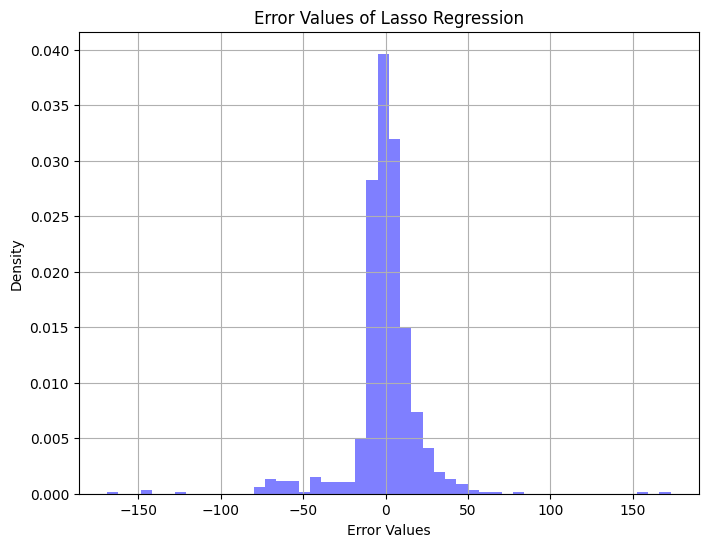

In [ ]:
# visualisasi distribusi error antara nilai aktual dan prediksi model
error_values_ls = y_test - y_pred_ls

plt.figure(figsize=(8, 6))
plt.hist(error_values_ls, bins=50, density=True, color='blue', alpha=0.5)
plt.title('Error Values of Lasso Regression')
plt.xlabel('Error Values')
plt.ylabel('Density')
plt.grid(True)
plt.show()